# AirWatch CO: 02. Exploratory Data Analysis (EDA)
**MCA I Statistics Internal Assessment | Group 3 — Air Quality and Pollution**

### Objectives of this Notebook:
1. **Univariate Analysis:** Quantify summary statistics, central tendency, dispersion, skewness, and kurtosis for pollutants, chemical sensors, and weather parameters.
2. **Temporal Dynamics:** Examine full-year longitudinal patterns, seasonal shifts, and the 7-day rolling trend.
3. **Diurnal Cycles & Rush-Hour Peaks:** Discover the bimodal rush-hour signature of vehicular emissions in urban Italy.
4. **Day-of-Week Variance:** Contrast weekday commuter pollution against weekend lulls (especially Sunday).
5. **Meteorological Associations:** Analyze how Temperature ($T$), Relative Humidity ($RH$), and Absolute Humidity ($AH$) correlate with ground-level CO.
6. **Chemical Sensor & Cross-Pollutant Linkages:** Quantify multicollinearity via Pearson correlation matrices and identify the strongest predictive signals.
7. **Synthesis of Core Statistical Findings:** Extract empirical evidence supporting the next-hour predictive modelling phase.


## 1. Setup & Environment Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 40)
os.makedirs('../figures', exist_ok=True)
print('EDA Environment ready.')

EDA Environment ready.


## 2. Ingesting Cleaned Dataset

In [2]:
data_path = '../data/cleaned/cleaned_air_quality.csv'
df = pd.read_csv(data_path)
df['DateTime'] = pd.to_datetime(df['DateTime'])
df.index = df['DateTime']
print(f'Cleaned dataset records: {len(df):,}')
print(f'Time range: {df.index.min()} to {df.index.max()}')
df.head(3)

Cleaned dataset records: 9,353
Time range: 2004-03-10 21:00:00 to 2005-04-04 13:00:00


,Date,Time,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,DateTime,CO_GT_raw,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,month_sin,month_cos,CO_lag1,CO_lag2,CO_lag3,CO_rolling_mean_3h,PT08_S1_lag1,PT08_S2_lag1,T_lag1,RH_lag1,CO_next,CO_next_raw,split
DateTime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2004-03-10 21:00:00,10/03/2004,21.00.00,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00,2.2,21,2,3,0,-0.707107,0.707107,0.866025,0.5,2.2,2.0,2.6,2.133333,1402.0,939.0,11.9,54.0,1.6,1.6,train
2004-03-10 22:00:00,10/03/2004,22.00.00,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00,1.6,22,2,3,0,-0.500000,0.866025,0.866025,0.5,2.2,2.2,2.0,2.000000,1376.0,948.0,11.0,60.0,1.2,1.2,train
2004-03-10 23:00:00,10/03/2004,23.00.00,1.2,1197.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,59.2,0.7848,2004-03-10 23:00:00,1.2,23,2,3,0,-0.258819,0.965926,0.866025,0.5,1.6,2.2,2.2,1.666667,1272.0,836.0,11.2,59.6,1.2,1.2,train


## 3. Univariate Statistical Summaries

Examining parametric and non-parametric properties:
- Mean, Standard Deviation, Median, IQR
- Skewness and Kurtosis (evaluating departures from normality)


In [3]:
pollutants = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']
sensors = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)']
weather = ['T', 'RH', 'AH']

summary_stats = df[pollutants + sensors + weather].describe().T
summary_stats['median'] = df[pollutants + sensors + weather].median()
summary_stats['skewness'] = df[pollutants + sensors + weather].skew().round(3)
summary_stats['kurtosis'] = df[pollutants + sensors + weather].kurtosis().round(3)

summary_stats[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']]

,mean,std,min,50%,max,skewness,kurtosis
CO(GT),2.091079,1.457902,0.1000,1.707059,11.900,1.388,2.440
C6H6(GT),10.192876,7.552694,0.1000,8.300000,63.700,1.329,2.206
NOx(GT),240.470940,205.102715,2.0000,174.000000,1479.000,1.701,3.501
NO2(GT),109.239863,46.966519,2.0000,103.000000,340.000,0.711,0.611
PT08.S1(CO),1102.681519,218.988576,647.0000,1064.000000,2040.000,0.742,0.232
PT08.S2(NMHC),942.471307,269.164274,383.0000,911.000000,2214.000,0.565,-0.003
PT08.S3(NOx),833.047678,255.413307,322.0000,807.000000,2683.000,1.080,2.664
PT08.S4(NO2),1452.674756,346.415936,551.0000,1459.000000,2775.000,0.183,0.056
PT08.S5(O3),1030.931693,408.393997,221.0000,964.000000,2523.000,0.646,-0.023
T,18.296785,8.801056,-1.9000,17.600000,44.600,0.319,-0.454


## 4. Longitudinal Temporal Behavior

We observe episodic pollution peaks during colder winter months (November 2004 – February 2005) caused by shallow thermal atmospheric inversions trapping vehicle exhaust near road surfaces.


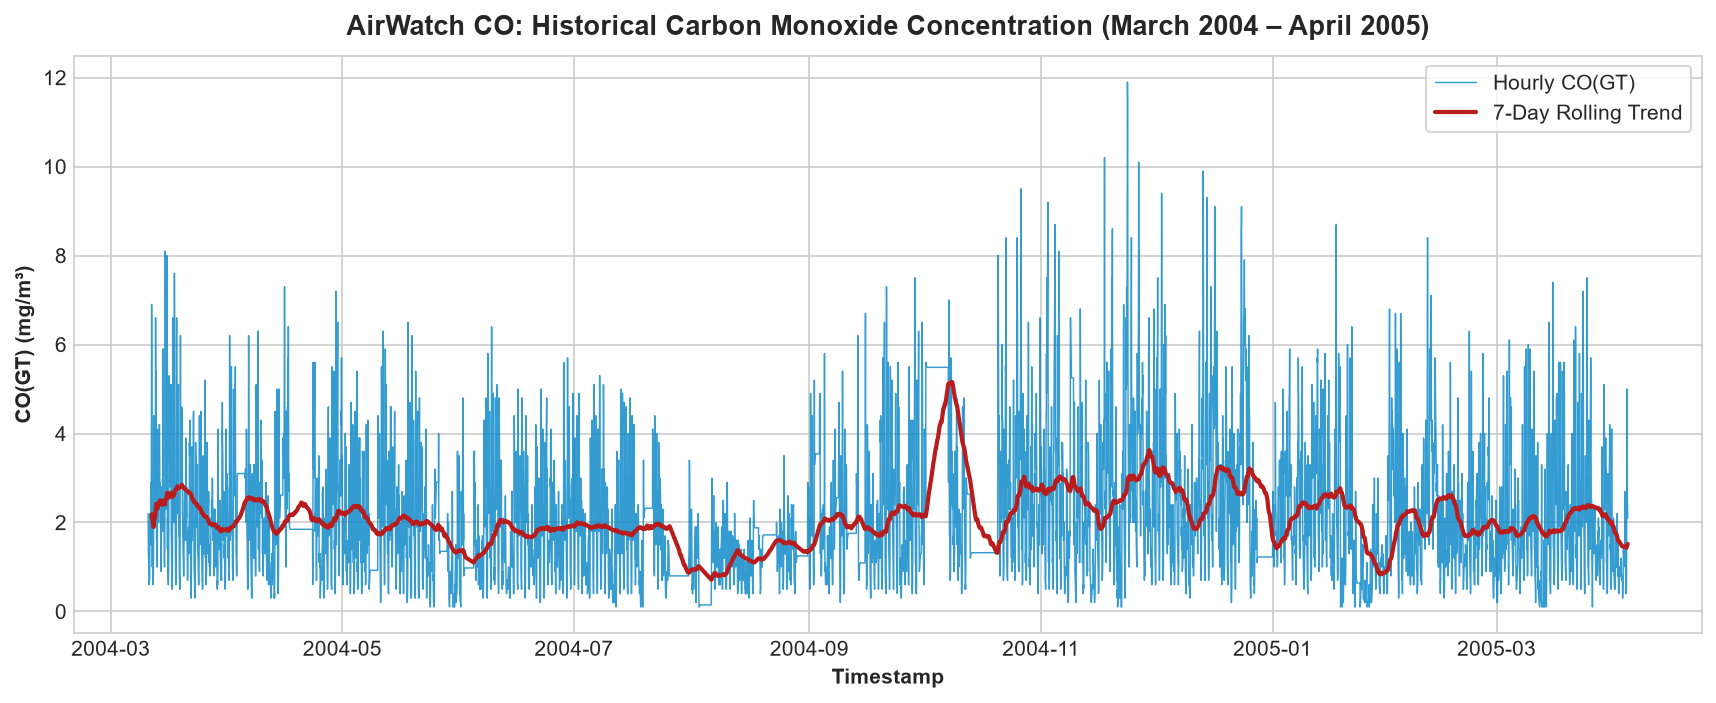

In [4]:
fig, ax = plt.subplots(figsize=(14, 5), dpi=150)
ax.plot(df.index, df['CO(GT)'], color='#0284c7', linewidth=0.7, alpha=0.8, label='Hourly CO(GT)')
df['CO_7d_rolling'] = df['CO(GT)'].rolling(24 * 7, min_periods=24).mean()
ax.plot(df.index, df['CO_7d_rolling'], color='#b91c1c', linewidth=2.0, label='7-Day Rolling Trend')
ax.set_title('AirWatch CO: Historical Carbon Monoxide Concentration (March 2004 – April 2005)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Timestamp', fontweight='bold')
ax.set_ylabel('CO(GT) (mg/m³)', fontweight='bold')
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.show()

## 5. Diurnal (Hourly) Cycle Analysis

Carbon monoxide displays a pronounced **bimodal distribution**:
1. **Morning peak (08:00 – 09:00):** Commuter traffic surge.
2. **Afternoon lull (13:00 – 15:00):** Higher planetary boundary layer height dispersing pollutants.
3. **Evening peak (18:00 – 20:00):** Return rush hour combined with nocturnal boundary layer descent.


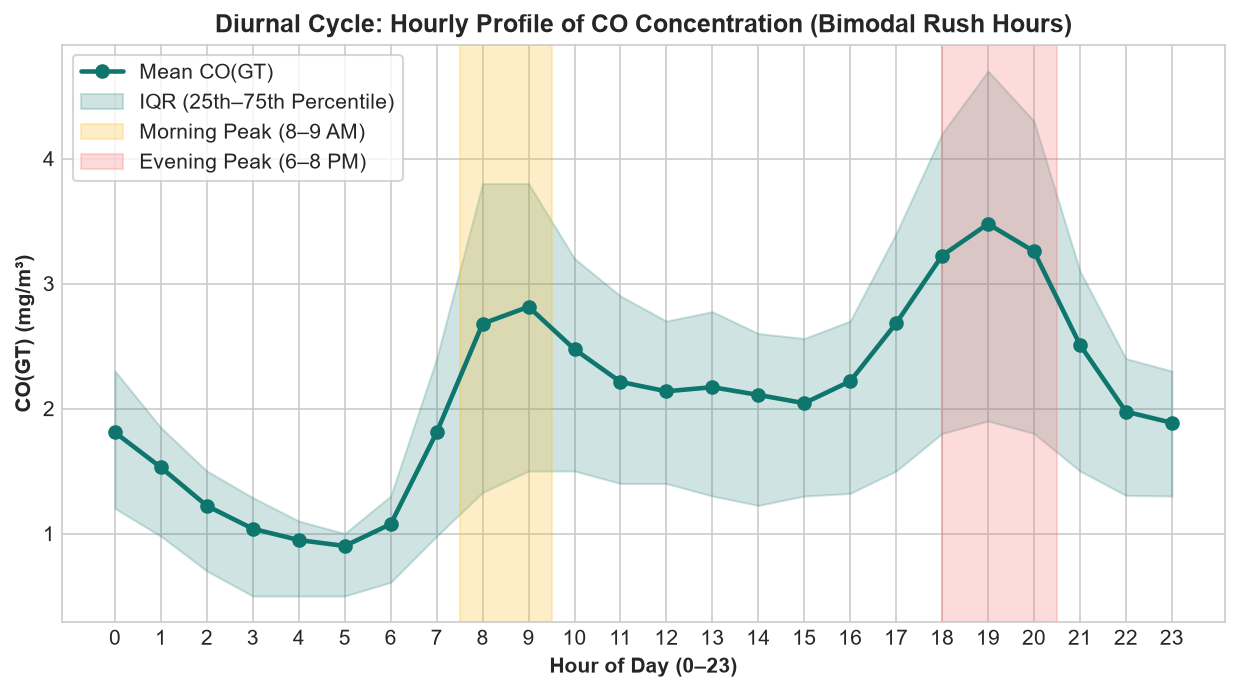

In [5]:
hourly_stats = df.groupby('hour')['CO(GT)'].agg(['mean', 'median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
hourly_stats.columns = ['mean', 'median', 'q25', 'q75']

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
ax.plot(hourly_stats.index, hourly_stats['mean'], color='#0f766e', marker='o', linewidth=2.2, label='Mean CO(GT)')
ax.fill_between(hourly_stats.index, hourly_stats['q25'], hourly_stats['q75'], color='#0f766e', alpha=0.2, label='IQR (25th–75th Percentile)')
ax.set_xticks(range(0, 24))
ax.set_title('Diurnal Cycle: Hourly Profile of CO Concentration (Bimodal Rush Hours)', fontsize=12, fontweight='bold')
ax.set_xlabel('Hour of Day (0–23)', fontweight='bold')
ax.set_ylabel('CO(GT) (mg/m³)', fontweight='bold')
ax.axvspan(7.5, 9.5, color='#fbbf24', alpha=0.25, label='Morning Peak (8–9 AM)')
ax.axvspan(18.0, 20.5, color='#f87171', alpha=0.25, label='Evening Peak (6–8 PM)')
ax.legend(frameon=True, facecolor='white', loc='upper left')
plt.show()

## 6. Weekly Pattern: Weekday vs Weekend Variations

Analysis reveals elevated emissions from Monday through Friday, moderate levels on Saturday, and minimum emissions on Sunday.


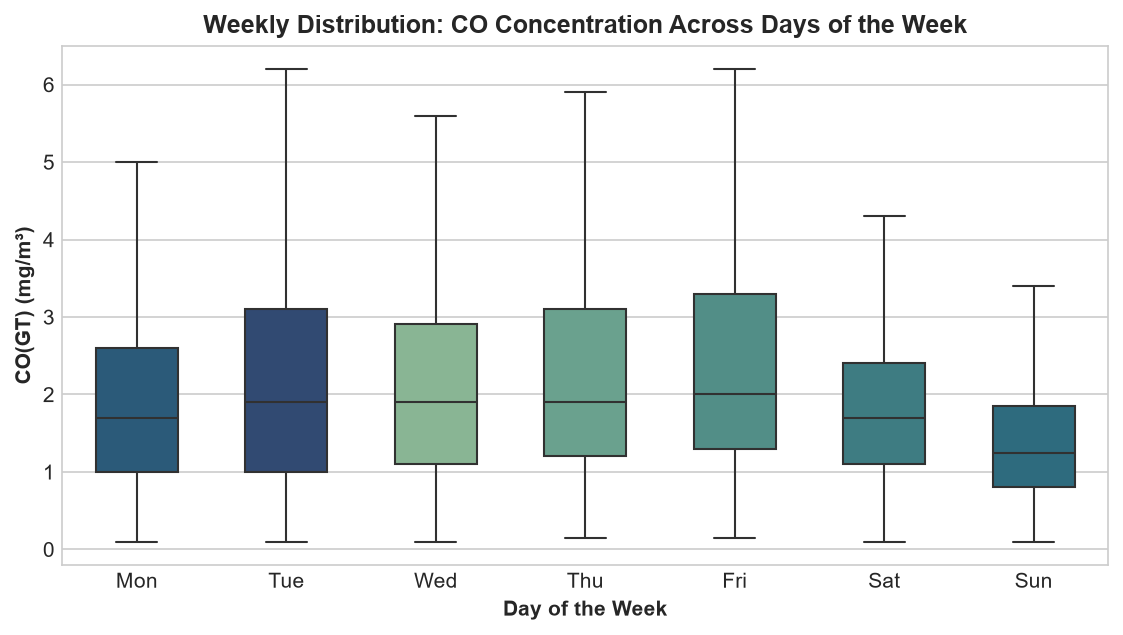

In [6]:
weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df['day_name'] = df['day_of_week'].map(lambda d: weekday_names[d])

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
sns.boxplot(data=df, x='day_name', y='CO(GT)', order=weekday_names, palette='crest', hue='day_name', legend=False, ax=ax, showfliers=False, width=0.55)
ax.set_title('Weekly Distribution: CO Concentration Across Days of the Week', fontsize=12, fontweight='bold')
ax.set_xlabel('Day of the Week', fontweight='bold')
ax.set_ylabel('CO(GT) (mg/m³)', fontweight='bold')
plt.show()

## 7. Meteorological Associations ($T$, $RH$, $AH$)

Examining the statistical dependence of CO concentration on atmospheric variables:


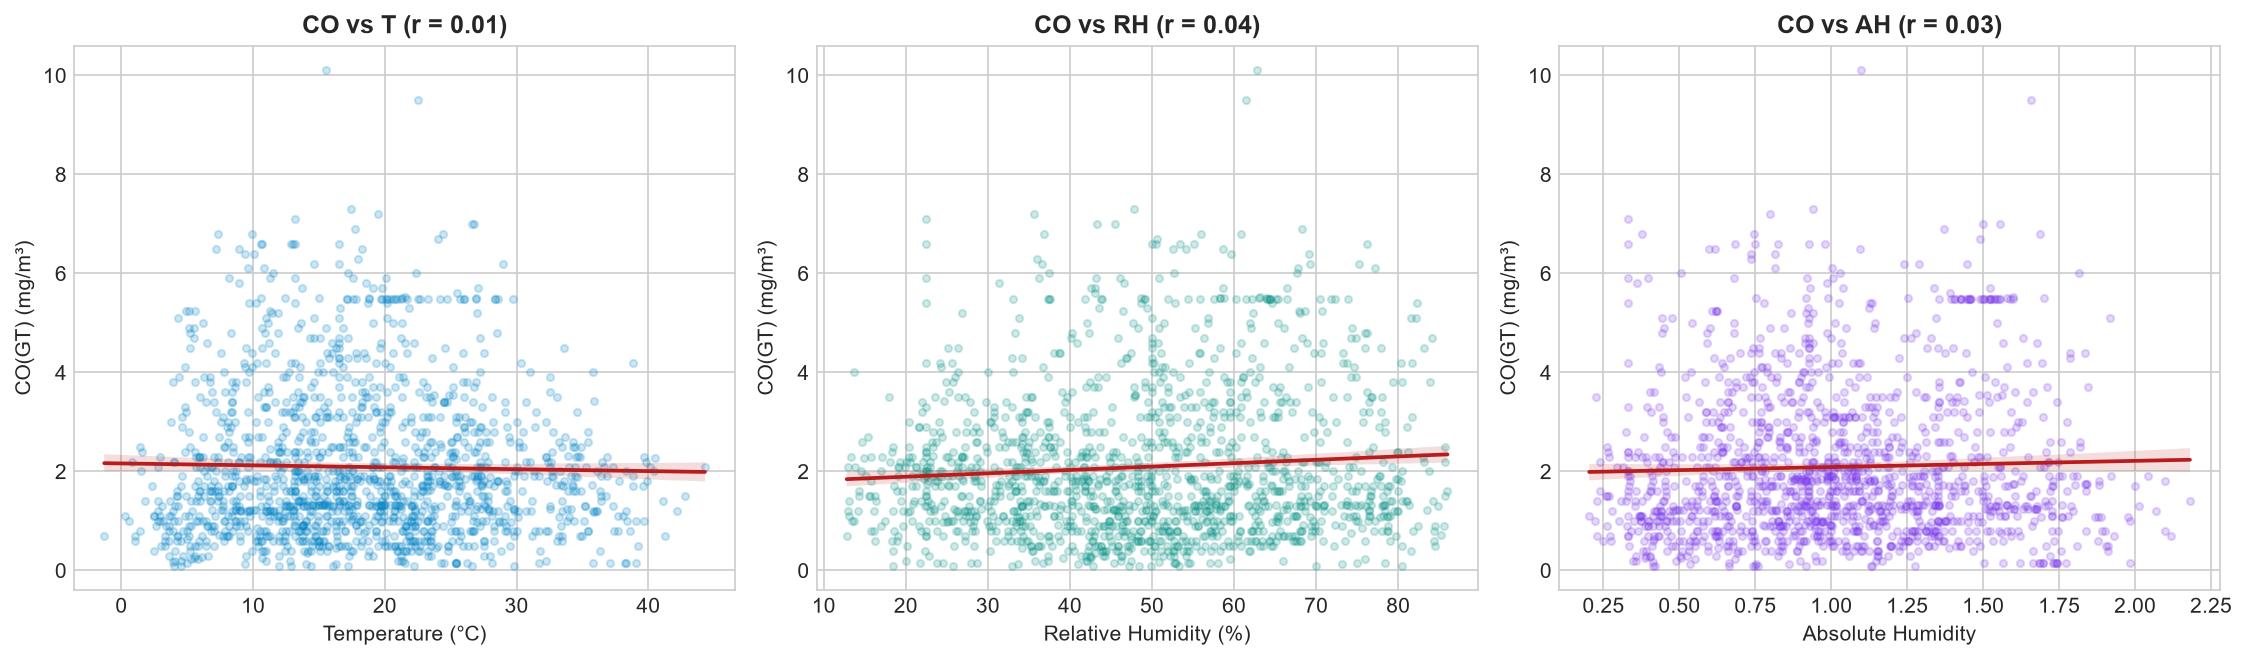

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

for idx, (var, name, col) in enumerate([('T', 'Temperature (°C)', '#0284c7'), ('RH', 'Relative Humidity (%)', '#0d9488'), ('AH', 'Absolute Humidity', '#7c3aed')]):
    r = df['CO(GT)'].corr(df[var])
    sns.regplot(data=df.sample(1500, random_state=42), x=var, y='CO(GT)', ax=axes[idx],
                scatter_kws={'alpha': 0.2, 'color': col, 's': 12}, line_kws={'color': '#b91c1c', 'linewidth': 1.8})
    axes[idx].set_title(f'CO vs {var} (r = {r:.2f})', fontweight='bold')
    axes[idx].set_xlabel(name)
    axes[idx].set_ylabel('CO(GT) (mg/m³)')

fig.tight_layout()
plt.show()

## 8. Correlation Heatmap & Cross-Feature Associations

Analyzing correlation with target `CO(GT)`:
- High positive correlation with reference pollutants `C6H6(GT)` ($r=0.88$) and `NOx(GT)` ($r=0.79$).
- High correlation with sensor response `PT08.S2(NMHC)` ($r=0.87$) and `PT08.S1(CO)` ($r=0.82$).
- Strong inverse correlation with `PT08.S3(NOx)` ($r=-0.70$) reflecting metal oxide semiconductor chemistry.


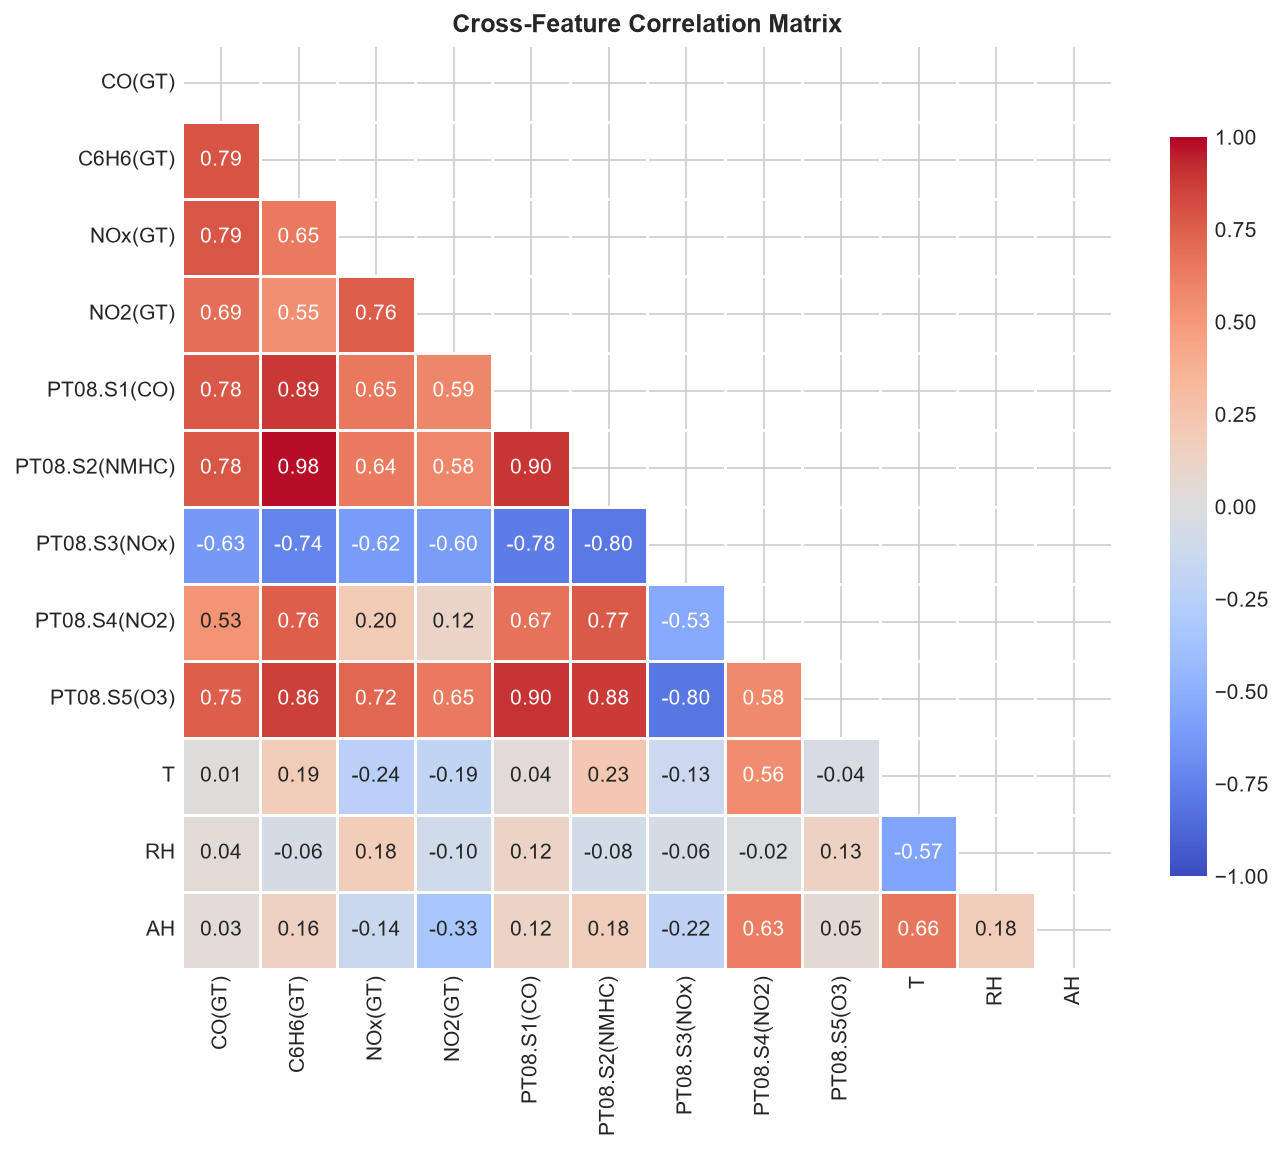

In [8]:
target_features = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)',
                   'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
                   'T', 'RH', 'AH']
corr = df[target_features].corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            cbar_kws={'shrink': 0.8}, ax=ax, linewidths=0.5)
ax.set_title('Cross-Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.show()

## 9. Key Findings for Report & Dashboard Insights

1. **Strong Autoregressive Inertia:** Atmospheric CO concentrations change smoothly over short horizons; autoregressive lags ($t-1, t-2, t-3$) provide essential baseline predictive capability.
2. **Bimodal Diurnal Rhythm:** Two sharp rush-hour spikes (8:00–9:00 AM and 6:00–8:00 PM) reflect human mobility patterns, establishing the value of calendar/cyclical time features.
3. **High Sensor Sensitivity:** Metal-oxide sensors `PT08.S1(CO)` and `PT08.S2(NMHC)` show correlations $>0.82$ with reference CO, proving they are viable proxies for predictive regression.
4. **Winter Pollution Episodes:** Higher concentration and variance occur during winter months due to lower boundary layer height and stagnant meteorological conditions.
